In [1]:
import pandas as pd
import numpy as np
from pathlib import Path

BASE = Path(r"C:\Users\Administrator\credit-scoring-lc")
df = pd.read_parquet(BASE / "data" / "processed" / "loans_clean.parquet")

train = df[df["split"] == "train"].copy()
test = df[df["split"] == "test"].copy()

print(train.shape, test.shape)

(262992, 26) (283026, 26)


In [2]:
# 1) 只用训练集，算出每个变量的上下限
limits = {
    "annual_inc": (train["annual_inc"].quantile(0.01), train["annual_inc"].quantile(0.99)),
    "dti":        (train["dti"].quantile(0.01),        train["dti"].quantile(0.99)),
    "revol_bal":  (train["revol_bal"].quantile(0.01),  train["revol_bal"].quantile(0.99)),
    "revol_util": (None,                               train["revol_util"].quantile(0.999)),
}

# 2) 把同一套上下限，同时用到训练集和测试集
for c, (lo, hi) in limits.items():
    train[c] = train[c].clip(lower=lo, upper=hi)
    test[c]  = test[c].clip(lower=lo, upper=hi)

# 3) 检查：截断后各变量的最小值和最大值
check = pd.DataFrame({
    "train_min": train[list(limits)].min(), "train_max": train[list(limits)].max(),
    "test_min":  test[list(limits)].min(),  "test_max":  test[list(limits)].max(),
})
check.round(1)

,train_min,train_max,test_min,test_max
annual_inc,18000.0,250000.0,18000.0,250000.0
dti,2.1,34.8,2.1,34.8
revol_bal,508.9,80964.1,508.9,80964.1
revol_util,0.0,102.2,0.0,102.2


In [3]:
cols = ["open_acc", "total_acc", "credit_hist_months", "pub_rec", "delinq_2yrs"]
q = train[cols].quantile([0.50, 0.99, 0.999]).T
q["max"] = train[cols].max()
q["n_above_99.9%"] = [(train[c] > q.loc[c, 0.999]).sum() for c in cols]
q.round(1)

,0.5,0.99,0.999,max,n_above_99.9%
open_acc,10.0,27.0,37.0,84.0,216
total_acc,23.0,59.0,72.0,156.0,262
credit_hist_months,175.0,473.0,587.0,793.0,259
pub_rec,0.0,2.0,5.0,63.0,223
delinq_2yrs,0.0,4.0,8.0,29.0,234


In [4]:
extra = ["open_acc", "total_acc", "credit_hist_months"]

for c in extra:
    hi = train[c].quantile(0.999)      # 上限只用训练集算
    train[c] = train[c].clip(upper=hi)
    test[c]  = test[c].clip(upper=hi)
    limits[c] = (None, hi)             # 记进清单，之后保存规则时用

pd.DataFrame({"train_max": train[extra].max(), "test_max": test[extra].max()})

,train_max,test_max
open_acc,37.0,37.0
total_acc,72.0,72.0
credit_hist_months,587.0,587.0


In [5]:
# 1) 先建"缺失标记"，必须在填补之前做
for d in (train, test):
    d["emp_length_missing"] = d["emp_length_yrs"].isna().astype(int)
    d["has_delinq_record"]  = d["mths_since_last_delinq"].notna().astype(int)
    d["has_public_record"]  = d["mths_since_last_record"].notna().astype(int)

# 2) 中位数只用训练集算
fill_cols = ["emp_length_yrs", "mths_since_last_delinq", "mths_since_last_record",
             "dti", "revol_util"]
med = {c: train[c].median() for c in fill_cols}

# 3) 同一套中位数填到训练集和测试集
for d in (train, test):
    for c, m in med.items():
        d[c] = d[c].fillna(m)

print(med)
print("剩余缺失值：", train.isna().sum().sum(), test.isna().sum().sum())

{'emp_length_yrs': np.float64(6.0), 'mths_since_last_delinq': np.float64(31.0), 'mths_since_last_record': np.float64(75.0), 'dti': np.float64(16.8), 'revol_util': np.float64(56.1)}
剩余缺失值： 0 0


In [6]:
for d in (train, test):
    d["purpose"] = d["purpose"].replace({"renewable_energy": "other", "wedding": "other"})
    d["home_ownership"] = d["home_ownership"].replace({"ANY": "OWN"})

print(train["purpose"].value_counts(), "\n")
print(train["home_ownership"].value_counts(), "\n")
print(test["home_ownership"].value_counts())

purpose
debt_consolidation    152387
credit_card            66200
home_improvement       14093
other                  13589
major_purchase          4718
medical                 2653
small_business          2647
car                     2415
moving                  1699
vacation                1587
house                   1004
Name: count, dtype: int64 

home_ownership
MORTGAGE    126492
RENT        111311
OWN          25189
Name: count, dtype: int64 

home_ownership
MORTGAGE    129762
RENT        121463
OWN          31801
Name: count, dtype: int64


In [7]:
demo = pd.DataFrame({"home": ["RENT", "OWN", "MORTGAGE", "RENT"]})
pd.get_dummies(demo, columns=["home"], drop_first=True, dtype=int)

,home_OWN,home_RENT
0,0,1
1,1,0
2,0,0
3,0,1


In [8]:
cat_use = ["purpose", "home_ownership", "verification_status", "initial_list_status"]

train_d = pd.get_dummies(train, columns=cat_use, drop_first=True, dtype=int)
test_d  = pd.get_dummies(test,  columns=cat_use, drop_first=True, dtype=int)

# 让测试集的列和训练集完全一致（缺的补0，多的去掉）
test_d = test_d.reindex(columns=train_d.columns, fill_value=0)

print(train_d.shape, test_d.shape)
print([c for c in train_d.columns if c.startswith(("home_ownership", "verification_status", "initial_list_status"))])

(262992, 40) (283026, 40)
['home_ownership_OWN', 'home_ownership_RENT', 'verification_status_Source Verified', 'verification_status_Verified', 'initial_list_status_w']


In [9]:
import json

PROC = BASE / "data" / "processed"
train_d.to_parquet(PROC / "train_features.parquet", index=False)
test_d.to_parquet(PROC / "test_features.parquet", index=False)

rules = {
    "clip_limits": {c: [None if lo is None else float(lo), float(hi)]
                    for c, (lo, hi) in limits.items()},
    "median_fill": {c: float(m) for c, m in med.items()},
}
(BASE / "reports").mkdir(exist_ok=True)
(BASE / "reports" / "preprocessing_rules.json").write_text(
    json.dumps(rules, indent=2), encoding="utf-8")

print((PROC / "train_features.parquet").exists(),
      (PROC / "test_features.parquet").exists(),
      (BASE / "reports" / "preprocessing_rules.json").exists())

True True True


In [10]:
from sklearn.preprocessing import StandardScaler

# 1) 这三个变量按计划压成 0/1/2及以上
for d in (train_d, test_d):
    for c in ["delinq_2yrs", "pub_rec", "pub_rec_bankruptcies"]:
        d[c] = d[c].clip(upper=2)

# 2) 挑出用来预测的列：去掉标识、标签、州
drop_cols = ["id", "issue_date", "issue_year", "split", "default_flag", "addr_state"]
feature_cols = [c for c in train_d.columns if c not in drop_cols]

X_train, y_train = train_d[feature_cols], train_d["default_flag"]
X_test,  y_test  = test_d[feature_cols],  test_d["default_flag"]

# 3) 标准化：均值和标准差只用训练集算
scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_test_s  = scaler.transform(X_test)

print(len(feature_cols), X_train_s.shape, X_test_s.shape)
print(round(y_train.mean(), 4), round(y_test.mean(), 4))

34 (262992, 34) (283026, 34)
0.1319 0.1489


In [11]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from scipy.stats import ks_2samp

lr = LogisticRegression(max_iter=1000)
lr.fit(X_train_s, y_train)

p_train = lr.predict_proba(X_train_s)[:, 1]
p_test  = lr.predict_proba(X_test_s)[:, 1]

def ks_stat(y, p):
    y = np.asarray(y)
    return ks_2samp(p[y == 1], p[y == 0]).statistic

print("AUC  train:", round(roc_auc_score(y_train, p_train), 4),
      " test:", round(roc_auc_score(y_test, p_test), 4))
print("KS   train:", round(ks_stat(y_train, p_train), 4),
      " test:", round(ks_stat(y_test, p_test), 4))

AUC  train: 0.6557  test: 0.6604
KS   train: 0.2264  test: 0.2326


In [12]:
coef = pd.Series(lr.coef_[0], index=feature_cols).sort_values()
coef.round(3)

fico                                  -0.377
annual_inc                            -0.196
revol_bal                             -0.123
total_acc                             -0.104
purpose_credit_card                   -0.069
has_delinq_record                     -0.065
has_public_record                     -0.055
pub_rec_bankruptcies                  -0.042
credit_hist_months                    -0.027
initial_list_status_w                 -0.010
emp_length_yrs                        -0.003
mths_since_last_delinq                 0.012
purpose_house                          0.015
purpose_major_purchase                 0.017
purpose_vacation                       0.018
purpose_debt_consolidation             0.019
purpose_home_improvement               0.029
revol_util                             0.033
delinq_2yrs                            0.035
purpose_moving                         0.036
mths_since_last_record                 0.036
home_ownership_OWN                     0.039
purpose_me

In [13]:
pairs = [("open_acc", "total_acc"),
         ("pub_rec", "pub_rec_bankruptcies"),
         ("pub_rec", "has_public_record"),
         ("loan_amnt", "annual_inc"),
         ("fico", "revol_util")]

for a, b in pairs:
    print(f"{a:12s} vs {b:22s} 相关系数 = {train_d[a].corr(train_d[b]):.2f}")

open_acc     vs total_acc              相关系数 = 0.68
pub_rec      vs pub_rec_bankruptcies   相关系数 = 0.80
pub_rec      vs has_public_record      相关系数 = 0.95
loan_amnt    vs annual_inc             相关系数 = 0.50
fico         vs revol_util             相关系数 = -0.44


In [14]:
drop_v2 = ["has_public_record", "open_acc"]
cols_v2 = [c for c in feature_cols if c not in drop_v2]

sc2 = StandardScaler().fit(train_d[cols_v2])
Xtr2 = sc2.transform(train_d[cols_v2])
Xte2 = sc2.transform(test_d[cols_v2])

lr2 = LogisticRegression(max_iter=1000).fit(Xtr2, y_train)
p_tr2 = lr2.predict_proba(Xtr2)[:, 1]
p_te2 = lr2.predict_proba(Xte2)[:, 1]

print("v1 (34个变量) AUC test:", round(roc_auc_score(y_test, p_test), 4),
      " KS test:", round(ks_stat(y_test, p_test), 4))
print("v2 (32个变量) AUC test:", round(roc_auc_score(y_test, p_te2), 4),
      " KS test:", round(ks_stat(y_test, p_te2), 4))

pd.Series(lr2.coef_[0], index=cols_v2)[
    ["pub_rec", "pub_rec_bankruptcies", "total_acc", "loan_amnt", "annual_inc"]].round(3)

v1 (34个变量) AUC test: 0.6604  KS test: 0.2326
v2 (32个变量) AUC test: 0.6586  KS test: 0.2296


pub_rec                 0.021
pub_rec_bankruptcies   -0.070
total_acc              -0.031
loan_amnt               0.155
annual_inc             -0.193
dtype: float64

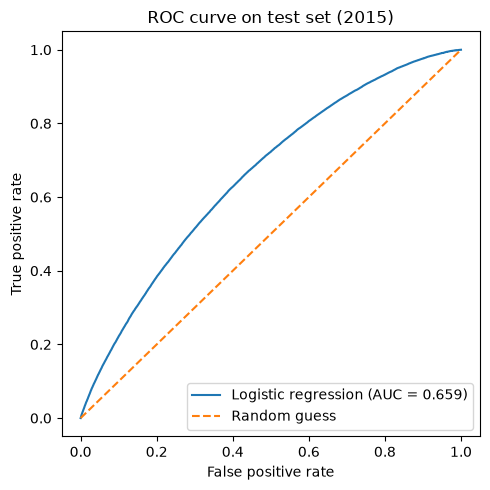

True


In [15]:
from sklearn.metrics import roc_curve
import matplotlib.pyplot as plt
import json

fpr, tpr, _ = roc_curve(y_test, p_te2)
fig, ax = plt.subplots(figsize=(5, 5))
ax.plot(fpr, tpr, label=f"Logistic regression (AUC = {roc_auc_score(y_test, p_te2):.3f})")
ax.plot([0, 1], [0, 1], linestyle="--", label="Random guess")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.set_title("ROC curve on test set (2015)")
ax.legend(loc="lower right")
plt.tight_layout()
fig.savefig(BASE / "reports" / "figures" / "roc_logistic_v2.png", dpi=150)
plt.show()

metrics = {
    "logistic_v2": {
        "auc_train": round(roc_auc_score(y_train, p_tr2), 4),
        "auc_test":  round(roc_auc_score(y_test,  p_te2), 4),
        "ks_train":  round(ks_stat(y_train, p_tr2), 4),
        "ks_test":   round(ks_stat(y_test,  p_te2), 4),
        "features":  cols_v2,
    }
}
(BASE / "reports" / "metrics_logistic_v2.json").write_text(
    json.dumps(metrics, indent=2), encoding="utf-8")
print((BASE / "reports" / "metrics_logistic_v2.json").exists())

In [16]:
# 1) 重存建模用的数据（含0/1/2压缩，这是模型实际用到的版本）
train_d.to_parquet(PROC / "train_features.parquet", index=False)
test_d.to_parquet(PROC / "test_features.parquet", index=False)

# 2) 补全规则文件：压缩规则 + v2 的变量清单 + 标准化参数
rules["cap_at_2"] = ["delinq_2yrs", "pub_rec", "pub_rec_bankruptcies"]
rules["merge_categories"] = {"purpose": {"renewable_energy": "other", "wedding": "other"},
                             "home_ownership": {"ANY": "OWN"}}
rules["logistic_v2_features"] = cols_v2
rules["scaler_v2"] = {"mean": dict(zip(cols_v2, map(float, sc2.mean_))),
                      "scale": dict(zip(cols_v2, map(float, sc2.scale_)))}
(BASE / "reports" / "preprocessing_rules.json").write_text(
    json.dumps(rules, indent=2), encoding="utf-8")

print(train_d[["delinq_2yrs", "pub_rec", "pub_rec_bankruptcies"]].max().tolist())

[2.0, 2.0, 2.0]
